# Question 9: Decision Tree Classification
To implement a Decision Tree Classifier to predict students' results using study hours, attendance and assignment scores.

In [12]:
# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [13]:
# Step 2: Create the dataset
data = {
    'Study_Hours': [2, 5, 1, 6, 3, 7, 2, 8, 4, 6],
    'Attendance': [60, 85, 50, 90, 70, 95, 55, 98, 75, 88],
    'Assignment_Score': [40, 80, 30, 90, 50, 95, 35, 98, 65, 85],
    'Result': [
        'Fail', 'Pass', 'Fail', 'Pass', 'Fail',
        'Pass', 'Fail', 'Pass', 'Pass', 'Pass'
    ]
}

df = pd.DataFrame(data)

In [14]:
# Step 3: Display the dataset
print("Student Dataset:")
print(df)

Student Dataset:
   Study_Hours  Attendance  Assignment_Score Result
0            2          60                40   Fail
1            5          85                80   Pass
2            1          50                30   Fail
3            6          90                90   Pass
4            3          70                50   Fail
5            7          95                95   Pass
6            2          55                35   Fail
7            8          98                98   Pass
8            4          75                65   Pass
9            6          88                85   Pass


In [15]:
# Step 4: Separate features (X) and target (y)
X = df[['Study_Hours', 'Attendance', 'Assignment_Score']]
y = df['Result']

In [16]:
# Step 5: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [17]:
# Step 6: Train the Decision Tree Classifier
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [18]:
# Step 7: Predict student results
y_pred = model.predict(X_test)

print("\nActual Results:", list(y_test))
print("Predicted Results:", list(y_pred))


Actual Results: ['Fail', 'Pass', 'Pass']
Predicted Results: ['Fail', 'Pass', 'Pass']


In [19]:
# Step 8: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", accuracy)
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


Model Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



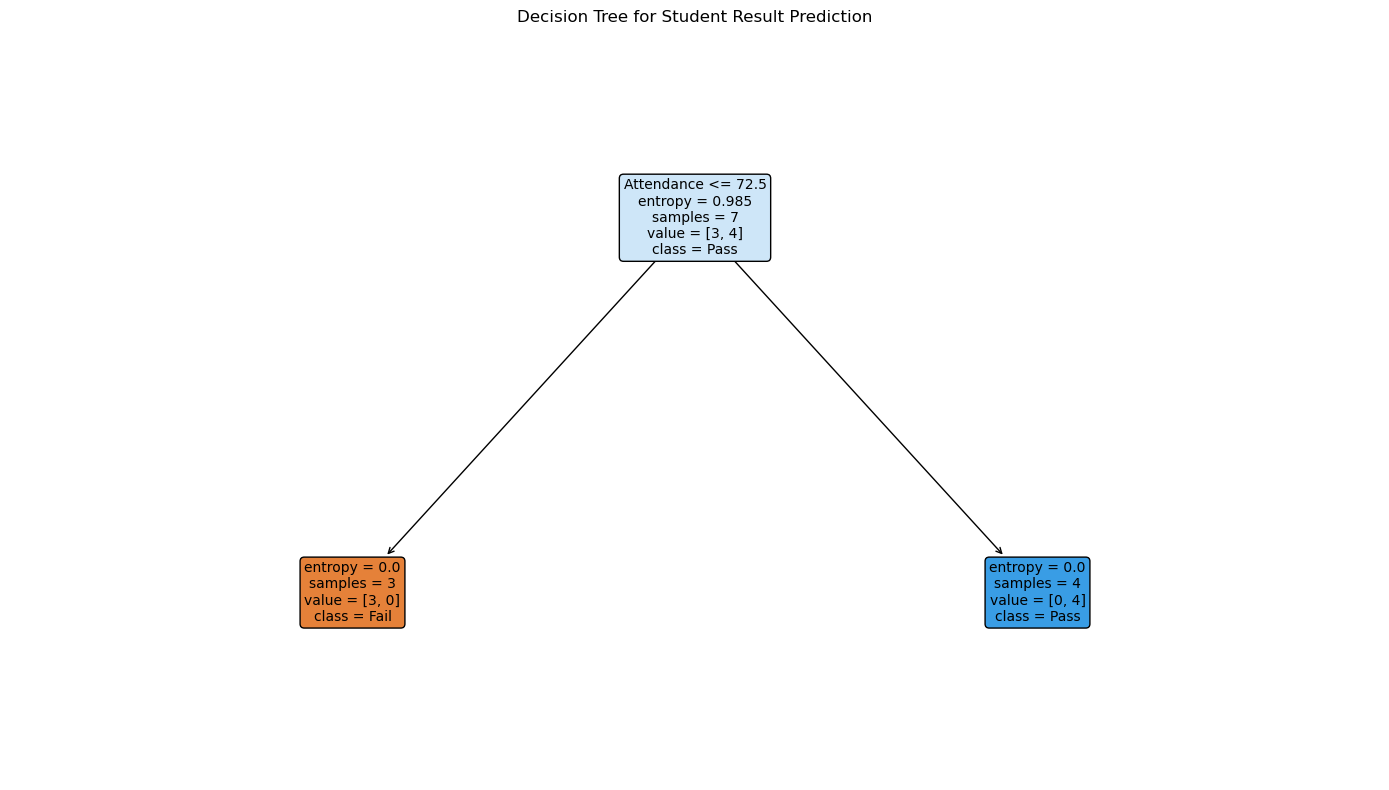

In [20]:
# Step 9: Visualize the decision tree
plt.figure(figsize=(14, 8))

plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=[str(cls) for cls in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Student Result Prediction")
plt.tight_layout()
plt.show()

In [21]:
# Step 10: Predict the result for a new student
new_student = pd.DataFrame({
    'Study_Hours': [5],
    'Attendance': [80],
    'Assignment_Score': [75]
})

prediction = model.predict(new_student)

print("\nNew Student Details:")
print(new_student)

print("Predicted Student Result:", prediction[0])


New Student Details:
   Study_Hours  Attendance  Assignment_Score
0            5          80                75
Predicted Student Result: Pass
